# 01 - Data Preparation - Kelompok 1
**Mata Kuliah:** Sains Data &nbsp;|&nbsp; **Kelas:** A &nbsp;|&nbsp; **Dataset:** Online Retail II (UCI)

## Anggota Kelompok
| No | Nama | NIM |
|---|---|---|
| 1 | Akhmad Fajri Mubarak | 2108561113 |
| 2 | Nayla Lareina Widyastuti Seregar | 2408561001 |
| 3 | I Gusti Ayu Agung Arda Swari | 2408561002 |
| 4 | Si Ngurah Putu Juliarta | 2408561004 |
| 5 | I Nyoman Gede Wresa Maharamya | 2408561007 |

## Target Progres Tugas Akhir IV
1. Menyelesaikan tahapan sampai **data preparation** (visualisasi data, perbaikan *noise* data) sampai data **siap diproses pada model**.
2. File dikumpulkan dalam format `.ipynb`.

Notebook ini menyatukan **konsep cleaning & fitur dari tugas Seleksi Fitur** (label churn temporal, fitur terpilih) dengan **visualisasi dari Tugas Akhir III**, lalu menghasilkan **5 output** yang dipakai tahap modeling.

## Alur Data Preparation
```
online_retail_II.xlsx (mentah, 1.067.371 baris)
        │
        ▼  [Bagian 2-3] profil kualitas data → cleaning bertahap (7 tahap) + perbaikan noise
        │
  OUTPUT 1: transaksi clean ─────────────────────────────────────────────┐
        │                                                                │
        ├─▶ [Bagian 5] potong 90 hari terakhir (cutoff temporal)         │
        │       OUTPUT 2: transaksi clean tanpa 90 hari terakhir         │
        │             │                                                  │
        │             ▼  fitur RFM per pelanggan + label Churn           │
        │       OUTPUT 3: dataset siap Classification                    │
        │                                                                │
        ├─▶ [Bagian 7] fitur per pelanggan (seluruh periode)             │
        │       OUTPUT 4: dataset siap Clustering                        │
        │                                                                │
        └─▶ [Bagian 8] matriks keranjang Invoice × Produk ◀──────────────┘
                OUTPUT 5: dataset siap Association Rules
```

## Daftar Output (folder `data/`)
| No | File | Isi | Dipakai untuk |
|---|---|---|---|
| 1 | `01_transaksi_clean.csv` | Transaksi hasil cleaning (seluruh periode) | Sumber semua dataset |
| 2 | `02_transaksi_clean_tanpa_90_hari_terakhir.csv` | Transaksi clean **sebelum** cutoff (90 hari terakhir dihapus) | Sumber fitur Classification |
| 3 | `03_classification_ready.csv` & `03_classification_ready_scaled.csv` | `Recency`, `Frequency`, `Monetary`, `CustomerAge`, `RecencyRatio` + `Churn` + kolom `Split` (train/test) | Model Classification (prediksi churn) |
| 4 | `04_clustering_ready_scaled.csv` & `04_clustering_profil.csv` | 6 fitur (log1p + standardisasi) & variabel profil | Model Clustering (segmentasi) |
| 5 | `05_association_basket_onehot.pkl`, `05_association_transaksi.csv`, `05_association_daftar_produk.csv` | Matriks one-hot Invoice × Produk | Association Rules (Apriori/FP-Growth) |

## Cara Pakai
**Google Colab + Google Drive (disarankan)**
1. Buat folder di Google Drive: `MyDrive/KELOMPOK1_SAINSDATA/data/`, lalu taruh `online_retail_II.xlsx` ([UCI](https://archive.ics.uci.edu/dataset/502/online+retail+ii)) di sana.
2. Buka notebook ini di Colab → **Run All** → izinkan akses Google Drive saat diminta.
3. Semua output tersimpan di `MyDrive/KELOMPOK1_SAINSDATA/data/`.

**Lokal**: letakkan notebook di folder `notebooks/` dan data di `../data/`. Sel pertama otomatis memakai folder lokal bila tidak berjalan di Colab.

In [1]:
# ===== Lokasi proyek: Google Drive (Colab) atau folder lokal =====
from pathlib import Path
try:
    from google.colab import drive          # hanya ada di Google Colab
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/KELOMPOK1_SAINSDATA")
except ImportError:
    BASE = Path("..").resolve()              # lokal: notebook di folder notebooks/
(BASE / "data").mkdir(parents=True, exist_ok=True)
print("Folder proyek :", BASE)
print("Isi data/     :", sorted(p.name for p in (BASE / "data").iterdir()))

Mounted at /content/drive
Folder proyek : /content/drive/MyDrive/KELOMPOK1_SAINSDATA
Isi data/     : ['online_retail_II.xlsx']


In [2]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

## 1. Konfigurasi & Load Data
Semua parameter dikumpulkan di satu tempat. Fitur dasar berasal dari **hasil tugas Seleksi Fitur**, ditambah 2 fitur turunan dari `TenureDays` (versi 2):
- **Classification:** `Recency`, `Frequency`, `Monetary` (RFM) + `CustomerAge` + `RecencyRatio`. Kedua fitur tambahan menaikkan ROC-AUC di **20/20 fold** cross-validation (dibuktikan di notebook Modeling).
- **Clustering:** `Recency`, `Frequency`, `Monetary`, `AvgBasketValue`, `UniqueProducts` + `CustomerAge`. `CustomerAge` memisahkan **pelanggan baru** dari pelanggan yang sudah lama pergi. `TenureDays`, `ReturnRate`, `Country` untuk profil cluster.
- **Association:** item = produk (`Description`) dengan frekuensi ≥ 50 baris transaksi.

In [3]:
INPUT_FILE = BASE / "data" / "online_retail_II.xlsx"
OUTPUT_DIR = BASE / "data"
RANDOM_STATE = 42

CHURN_DAYS = 90                  # horizon label churn = panjang periode yang "dipotong"
TOP_N_COUNTRIES = 10             # negara di luar top-10 digabung menjadi 'Other'
IQR_FACTOR = 3                   # batas capping outlier: Q1 - 3*IQR s.d. Q3 + 3*IQR
TEST_SIZE = 0.25                 # porsi data uji Classification
MIN_ITEM_FREQ_FOR_BASKET = 50    # produk langka (< 50 kemunculan) dibuang dari basket
BASKET_COUNTRY = None            # None = semua negara

# kode StockCode yang bukan barang dagangan (ongkos kirim, biaya bank, penyesuaian, dll.)
NON_PRODUCT_CODES = {"POST", "DOT", "M", "D", "C2", "BANK CHARGES", "ADJUST", "ADJUST2",
                     "AMAZONFEE", "CRUK", "PADS", "S", "B", "TEST001", "TEST002",
                     "GIFT", "SAMPLES", "DCGS0000"}
NON_PRODUCT_PATTERN = re.compile(r"^(gift_?0001|dcgs)", re.IGNORECASE)

# fitur terpilih dari tugas Seleksi Fitur
FEATURES_CLASSIFICATION = ["Recency", "Frequency", "Monetary", "CustomerAge", "RecencyRatio"]
FEATURES_CLUSTERING = ["Recency", "Frequency", "Monetary", "AvgBasketValue", "UniqueProducts", "CustomerAge"]
PROFILE_CLUSTERING = ["TenureDays", "ReturnRate", "Country"]

os.makedirs(OUTPUT_DIR, exist_ok=True)

In [4]:
def load_data(path):
    # membaca semua sheet (Year 2009-2010 & Year 2010-2011) lalu digabung
    xls = pd.ExcelFile(path)
    frames = [pd.read_excel(xls, sheet_name=s).assign(SourceSheet=s) for s in xls.sheet_names]
    return pd.concat(frames, ignore_index=True)


raw = load_data(INPUT_FILE)
print(f"Data mentah: {raw.shape[0]:,} baris x {raw.shape[1]} kolom")
print("Sheet       :", raw["SourceSheet"].unique().tolist())
print("Periode     :", raw["InvoiceDate"].min(), "s.d.", raw["InvoiceDate"].max())
raw.head()

Data mentah: 1,067,371 baris x 9 kolom
Sheet       : ['Year 2009-2010', 'Year 2010-2011']
Periode     : 2009-12-01 07:45:00 s.d. 2011-12-09 12:50:00


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SourceSheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010


## 2. Memahami Kualitas Data Mentah
Sebelum membersihkan, dicek dulu **jenis noise** apa saja yang ada dan seberapa banyak. Hasil cek ini yang menjadi dasar setiap tahap cleaning di Bagian 3.

In [5]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 9 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
 8   SourceSheet  1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(5)
memory usage: 73.3+ MB


In [6]:
sc_raw = raw["StockCode"].astype(str).str.strip()
noise_profile = pd.Series({
    "Customer ID kosong": raw["Customer ID"].isna().sum(),
    "Description kosong": raw["Description"].isna().sum(),
    "Baris duplikat persis": raw.duplicated().sum(),
    "Invoice batal/retur (awalan 'C')": raw["Invoice"].astype(str).str.startswith("C").sum(),
    "Quantity <= 0": (raw["Quantity"] <= 0).sum(),
    "Price <= 0": (raw["Price"] <= 0).sum(),
    "Kode non-produk (POST, M, ...)": (sc_raw.str.upper().isin(NON_PRODUCT_CODES)
                                        | sc_raw.str.match(NON_PRODUCT_PATTERN)).sum(),
}, name="Jumlah baris").to_frame()
noise_profile["% dari data"] = (noise_profile["Jumlah baris"] / len(raw) * 100).round(2)
noise_profile

,Jumlah baris,% dari data
Customer ID kosong,243007,22.77
Description kosong,4382,0.41
Baris duplikat persis,12133,1.14
Invoice batal/retur (awalan 'C'),19494,1.83
Quantity <= 0,22950,2.15
Price <= 0,6207,0.58
"Kode non-produk (POST, M, ...)",6089,0.57


In [7]:
raw[["Quantity", "Price"]].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(2)

,count,mean,std,min,1%,25%,50%,75%,99%,max
Quantity,1067371.0,9.94,172.71,-80995.00,-3.00,1.00,3.0,10.00,100.0,80995.0
Price,1067371.0,4.65,123.55,-53594.36,0.21,1.25,2.1,4.15,18.0,38970.0


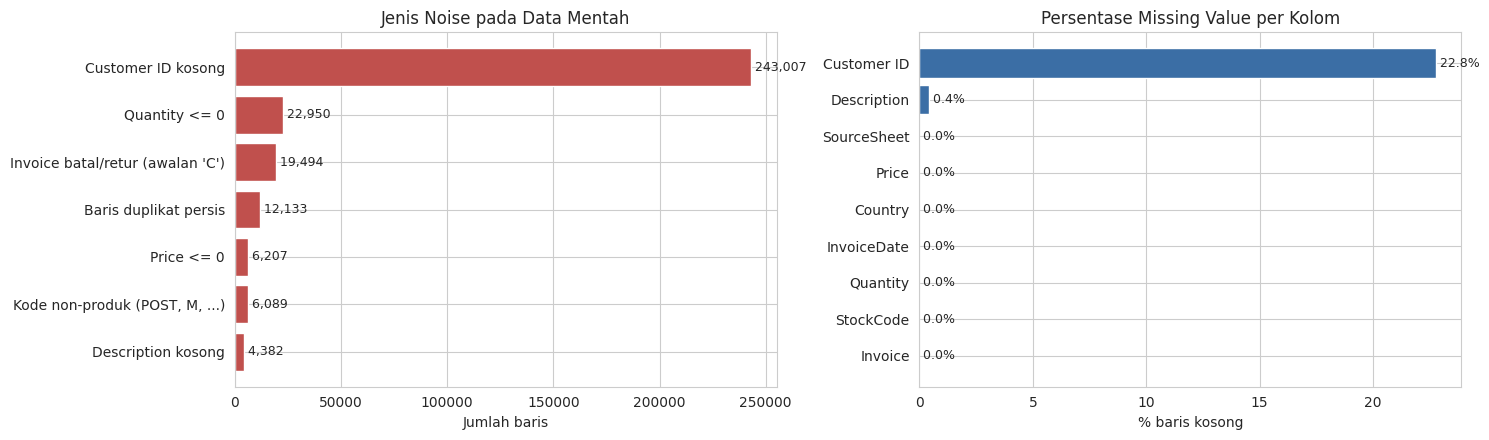

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

s = noise_profile["Jumlah baris"].sort_values()
axes[0].barh(s.index, s.values, color="#c0504d")
for i, v in enumerate(s.values):
    axes[0].text(v, i, f" {v:,}", va="center", fontsize=9)
axes[0].set_title("Jenis Noise pada Data Mentah")
axes[0].set_xlabel("Jumlah baris")

miss = raw.isna().mean().sort_values() * 100
axes[1].barh(miss.index, miss.values, color="#3b6ea5")
for i, v in enumerate(miss.values):
    axes[1].text(v, i, f" {v:.1f}%", va="center", fontsize=9)
axes[1].set_title("Persentase Missing Value per Kolom")
axes[1].set_xlabel("% baris kosong")

plt.tight_layout(); plt.show()

**Temuan kualitas data:**
- **Missing value** hanya ada di `Customer ID` (± 23 %) dan sedikit di `Description`. Tanpa `Customer ID`, transaksi tidak bisa diagregasi ke level pelanggan.
- **Duplikat**, **invoice batal/retur** (awalan `C`, Quantity negatif), **Price ≤ 0**, dan **kode non-produk** (`POST`, `M`, `BANK CHARGES`, ...) adalah noise yang tidak mewakili pembelian barang.
- **Outlier ekstrem**: `Quantity` minimum ≈ −80.995 dan maksimum ≈ 80.995, padahal persentil 99 % hanya ratusan. `Price` juga punya nilai puluhan ribu, jauh dari harga wajar.

## 3. Cleaning Bertahap (Perbaikan Noise)
Cleaning dilakukan **satu tahap per cell** agar jelas apa yang dibuang dan alasannya. Setiap tahap dicatat ke `cleaning_log`.

| Tahap | Aksi | Alasan |
|---|---|---|
| 1 | Standardisasi tipe & spasi | Teks yang beda spasi/huruf kapital dianggap berbeda, sehingga duplikat & kode non-produk lolos |
| 2 | Hapus duplikat | Baris yang tercatat dua kali menggandakan transaksi |
| 3 | Tandai invoice batal (`IsCancelled`) | **Tidak dibuang**: dipakai untuk fitur `ReturnRate`, tetapi tidak dihitung sebagai pembelian |
| 4 | Hapus baris tanpa `Customer ID` | Analisis pelanggan butuh ID yang valid |
| 5 | Hapus kode non-produk | Ongkos kirim, biaya bank, penyesuaian, dll. bukan barang yang dibeli |
| 6 | Hapus `Price ≤ 0` | Harga nol/negatif = data rusak atau penyesuaian, bukan jual-beli |
| 7 | Capping outlier IQR × 3 | Nilai ekstrem dipangkas (bukan dibuang) agar jumlah data tetap terjaga |

In [9]:
cleaning_log = []

def log_step(step, before, after, note):
    # mencatat jumlah baris sebelum & sesudah setiap tahap cleaning
    cleaning_log.append({"Tahap": step, "Sebelum": len(before), "Sesudah": len(after),
                         "Dibuang": len(before) - len(after), "Keterangan": note})
    print(f"{step}: {len(before):,} -> {len(after):,} baris (dibuang {len(before) - len(after):,})")

### Tahap 1 - Standardisasi tipe data & spasi

In [10]:
df = raw.copy()
for c in ["Invoice", "StockCode", "Country"]:
    df[c] = df[c].astype(str).str.strip()
df["Description"] = df["Description"].astype(str).str.strip().str.upper()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

log_step("1. Standardisasi tipe & spasi", raw, df, "Tidak membuang baris")
df[["Invoice", "StockCode", "Description", "Country"]].dtypes

1. Standardisasi tipe & spasi: 1,067,371 -> 1,067,371 baris (dibuang 0)


,0
Invoice,object
StockCode,object
Description,object
Country,object


### Tahap 2 - Hapus baris duplikat

In [11]:
before = df
print("Contoh baris duplikat:")
display(df[df.duplicated(keep=False)].sort_values(["Invoice", "StockCode"]).head(4))

df = df.drop_duplicates()
log_step("2. Hapus duplikat", before, df, "Baris identik di semua kolom")

Contoh baris duplikat:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SourceSheet
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom,Year 2009-2010
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom,Year 2009-2010
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,Year 2009-2010
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,Year 2009-2010


2. Hapus duplikat: 1,067,371 -> 1,055,238 baris (dibuang 12,133)


### Tahap 3 - Tandai invoice batal/retur (tidak dibuang)

In [12]:
df["IsCancelled"] = df["Invoice"].str.startswith("C")
log_step("3. Tandai invoice batal", df, df, "Ditandai IsCancelled; dipakai untuk ReturnRate")
print(f"Baris invoice batal: {df['IsCancelled'].sum():,} ({df['IsCancelled'].mean():.1%})")
print(f"Quantity negatif pada invoice batal: {(df.loc[df['IsCancelled'], 'Quantity'] < 0).mean():.1%} baris")

3. Tandai invoice batal: 1,055,238 -> 1,055,238 baris (dibuang 0)
Baris invoice batal: 19,433 (1.8%)
Quantity negatif pada invoice batal: 100.0% baris


### Tahap 4 - Hapus baris tanpa `Customer ID`

In [13]:
before = df
df = df[df["Customer ID"].notnull()].copy()
df["Customer ID"] = df["Customer ID"].astype(int)
log_step("4. Hapus Customer ID kosong", before, df, "Tidak bisa dipetakan ke pelanggan")

4. Hapus Customer ID kosong: 1,055,238 -> 812,368 baris (dibuang 242,870)


### Tahap 5 - Hapus kode non-produk

In [14]:
before = df
mask_non_product = (df["StockCode"].str.upper().isin(NON_PRODUCT_CODES)
                    | df["StockCode"].str.match(NON_PRODUCT_PATTERN))
print("Kode non-produk yang dibuang:")
display(df.loc[mask_non_product].groupby("StockCode")["Description"]
          .agg(Jumlah="size", Contoh="first").sort_values("Jumlah", ascending=False).head(8))

df = df[~mask_non_product].copy()
log_step("5. Hapus kode non-produk", before, df, "POSTAGE, MANUAL, BANK CHARGES, dll.")

Kode non-produk yang dibuang:


,Jumlah,Contoh
StockCode,,
POST,2019,POSTAGE
M,1104,MANUAL
C2,259,CARRIAGE
D,174,DISCOUNT
ADJUST,61,ADJUSTMENT BY JOHN ON 26/01/2010 16
BANK CHARGES,38,BANK CHARGES
PADS,19,PADS TO MATCH ALL CUSHIONS
DOT,16,DOTCOM POSTAGE


5. Hapus kode non-produk: 812,368 -> 808,643 baris (dibuang 3,725)


### Tahap 6 - Hapus `Price <= 0`

In [15]:
before = df
df = df[df["Price"] > 0].copy()
log_step("6. Hapus Price <= 0", before, df, "Harga nol/negatif bukan transaksi riil")

6. Hapus Price <= 0: 808,643 -> 808,582 baris (dibuang 61)


### Tahap 7 - Capping outlier `Quantity` & `Price` (IQR × 3)
Nilai di luar `[Q1 − 3·IQR, Q3 + 3·IQR]` dipangkas ke batasnya (*winsorize*). Faktor 3 (bukan 1,5) dipakai karena data retail memang miring: pembelian grosir masih wajar, yang dipangkas hanya nilai yang sangat ekstrem. Bila batas bawah negatif, batas bawah tidak dipakai agar `Quantity` negatif milik invoice retur tetap utuh.

In [16]:
before_cap = df.copy()   # disimpan untuk visualisasi sebelum vs sesudah capping

def cap_iqr(data, cols, factor=IQR_FACTOR):
    # winsorize kolom numerik dengan batas IQR; mengembalikan data & tabel batas
    data = data.copy()
    rows = []
    for col in cols:
        q1, q3 = data[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        low, high = q1 - factor * iqr, q3 + factor * iqr
        low_used = low if low > 0 else data[col].min()
        n_low, n_high = (data[col] < low_used).sum(), (data[col] > high).sum()
        data[col] = data[col].clip(lower=low_used, upper=high)
        rows.append({"Kolom": col, "Q1": q1, "Q3": q3, "IQR": iqr, "Batas bawah": low,
                     "Batas atas": high, "Di-cap bawah": n_low, "Di-cap atas": n_high})
    return data, pd.DataFrame(rows).set_index("Kolom")


df, cap_table = cap_iqr(df, ["Quantity", "Price"])
log_step("7. Capping outlier IQR x3", before_cap, df, "Nilai ekstrem dipangkas, baris tidak dibuang")
cap_table.round(2)

7. Capping outlier IQR x3: 808,582 -> 808,582 baris (dibuang 0)


,Q1,Q3,IQR,Batas bawah,Batas atas,Di-cap bawah,Di-cap atas
Kolom,,,,,,,
Quantity,2.00,12.00,10.0,-28.00,42.00,0,37269
Price,1.25,3.75,2.5,-6.25,11.25,0,18147


### Kolom turunan & ringkasan cleaning

In [17]:
df["TotalPrice"] = df["Quantity"] * df["Price"]
clean = df.reset_index(drop=True)

log_df = pd.DataFrame(cleaning_log).set_index("Tahap")
log_df["% sisa dari mentah"] = (log_df["Sesudah"] / len(raw) * 100).round(2)
log_df

,Sebelum,Sesudah,Dibuang,Keterangan,% sisa dari mentah
Tahap,,,,,
1. Standardisasi tipe & spasi,1067371,1067371,0,Tidak membuang baris,100.00
2. Hapus duplikat,1067371,1055238,12133,Baris identik di semua kolom,98.86
3. Tandai invoice batal,1055238,1055238,0,Ditandai IsCancelled; dipakai untuk ReturnRate,98.86
4. Hapus Customer ID kosong,1055238,812368,242870,Tidak bisa dipetakan ke pelanggan,76.11
5. Hapus kode non-produk,812368,808643,3725,"POSTAGE, MANUAL, BANK CHARGES, dll.",75.76
6. Hapus Price <= 0,808643,808582,61,Harga nol/negatif bukan transaksi riil,75.75
7. Capping outlier IQR x3,808582,808582,0,"Nilai ekstrem dipangkas, baris tidak dibuang",75.75


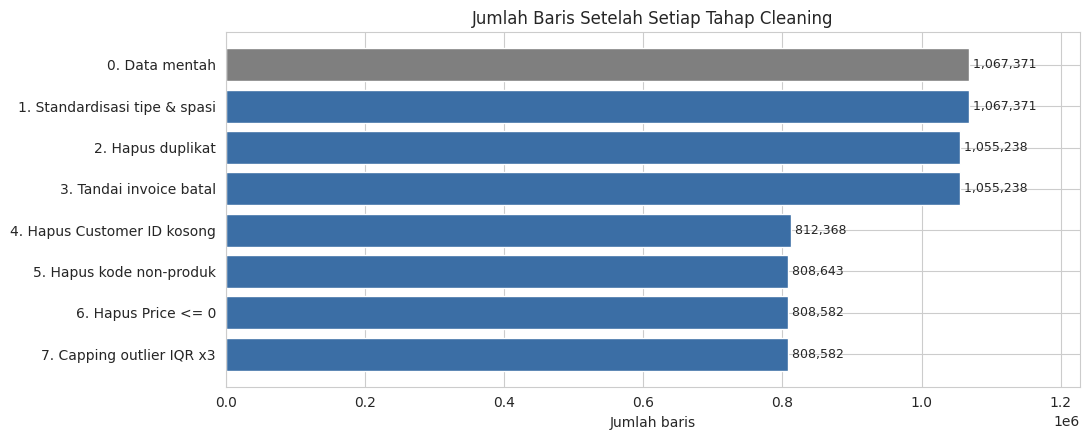

In [18]:
fig, ax = plt.subplots(figsize=(11, 4.5))
labels = ["0. Data mentah"] + list(log_df.index)
values = [len(raw)] + log_df["Sesudah"].tolist()
ax.barh(labels[::-1], values[::-1], color=["#3b6ea5"] * len(log_df) + ["#7f7f7f"])
for i, v in enumerate(values[::-1]):
    ax.text(v, i, f" {v:,}", va="center", fontsize=9)
ax.set_title("Jumlah Baris Setelah Setiap Tahap Cleaning")
ax.set_xlabel("Jumlah baris")
ax.set_xlim(0, len(raw) * 1.15)
plt.tight_layout(); plt.show()

**Validasi hasil cleaning.** Semua pengecekan harus bernilai `True`.

In [19]:
q_high, p_high = cap_table.loc["Quantity", "Batas atas"], cap_table.loc["Price", "Batas atas"]
checks = pd.Series({
    "Customer ID tidak ada yang kosong": clean["Customer ID"].notna().all(),
    "Semua Price > 0": (clean["Price"] > 0).all(),
    "Tidak ada kode non-produk": not (clean["StockCode"].str.upper().isin(NON_PRODUCT_CODES)
                                      | clean["StockCode"].str.match(NON_PRODUCT_PATTERN)).any(),
    "Quantity <= batas atas IQR": (clean["Quantity"] <= q_high).all(),
    "Price <= batas atas IQR": (clean["Price"] <= p_high).all(),
    "Quantity negatif hanya pada invoice batal": (clean.loc[clean["Quantity"] < 0, "IsCancelled"]).all(),
}, name="Lolos")
assert checks.all(), checks[~checks]
checks.to_frame()

,Lolos
Customer ID tidak ada yang kosong,True
Semua Price > 0,True
Tidak ada kode non-produk,True
Quantity <= batas atas IQR,True
Price <= batas atas IQR,True
Quantity negatif hanya pada invoice batal,True


## 4. Visualisasi Data (Sebelum vs Sesudah Cleaning)
Visualisasi dari Tugas Akhir III dipakai untuk membuktikan efek cleaning dan memahami pola transaksi.

### 4.1 Sebaran Quantity vs Price (UK vs Luar UK)
Diambil sampel 60.000 baris pembelian dari masing-masing data agar plot tidak terlalu berat. Skala log hanya bisa menampilkan nilai positif, sehingga yang diplot adalah baris pembelian (`Quantity > 0`).

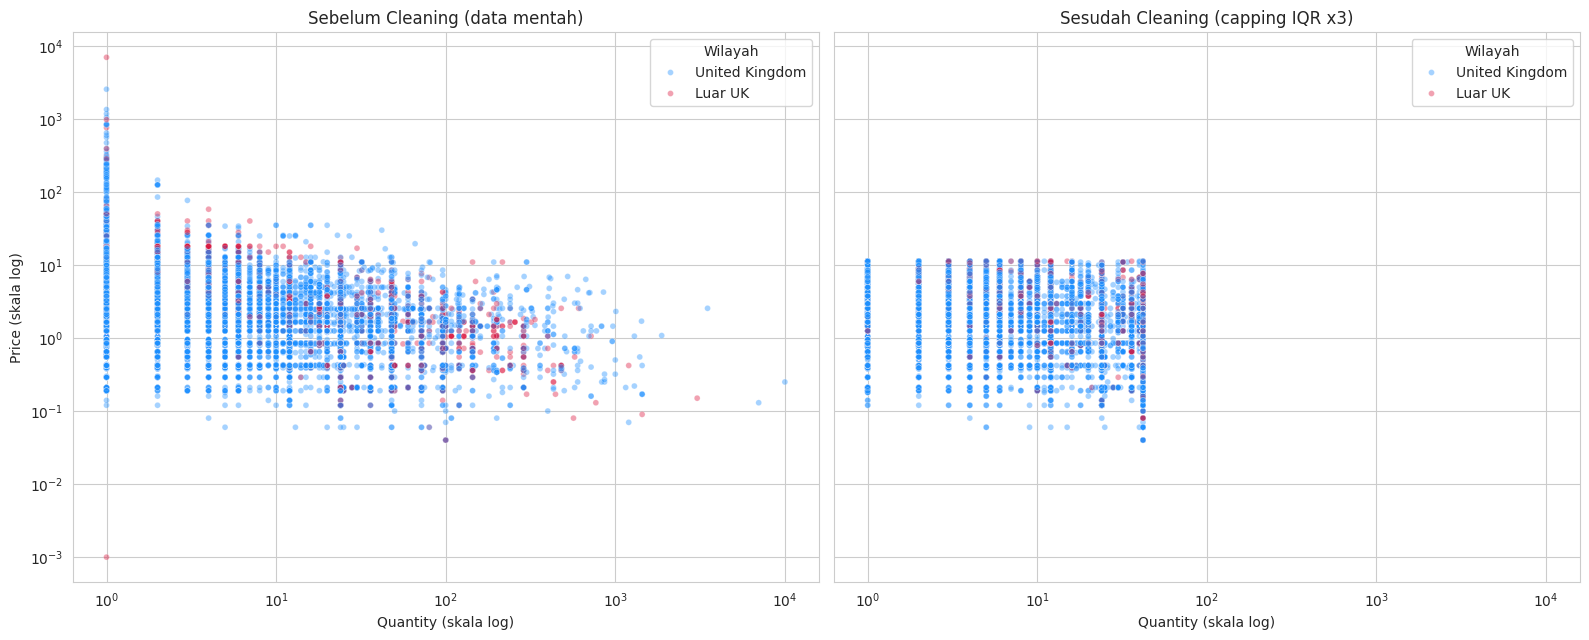

In [20]:
def purchases_sample(data, n=60_000):
    # baris pembelian (bukan batal, Quantity & Price positif) + penanda UK
    p = data[~data["Invoice"].astype(str).str.startswith("C")
             & (data["Quantity"] > 0) & (data["Price"] > 0)]
    p = p.sample(min(n, len(p)), random_state=RANDOM_STATE)
    return p.assign(Wilayah=np.where(p["Country"] == "United Kingdom", "United Kingdom", "Luar UK"))


fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharex=True, sharey=True)
for ax, (data, title) in zip(axes, [(raw, "Sebelum Cleaning (data mentah)"),
                                    (clean, "Sesudah Cleaning (capping IQR x3)")]):
    sns.scatterplot(data=purchases_sample(data), x="Quantity", y="Price", hue="Wilayah",
                    hue_order=["United Kingdom", "Luar UK"], palette=["dodgerblue", "crimson"],
                    alpha=0.4, s=18, ax=ax)
    ax.set(xscale="log", yscale="log", title=title,
           xlabel="Quantity (skala log)", ylabel="Price (skala log)")
plt.tight_layout(); plt.show()

Sebelum cleaning, titik menyebar sampai `Quantity` puluhan ribu dan `Price` ribuan (ongkos kirim, *manual adjustment*, pembelian ekstrem). Sesudah cleaning, sebaran terkumpul di rentang wajar dan dipangkas rapi pada batas atas IQR (garis "dinding" di kanan dan atas).

### 4.2 Boxplot Sebelum vs Sesudah Capping

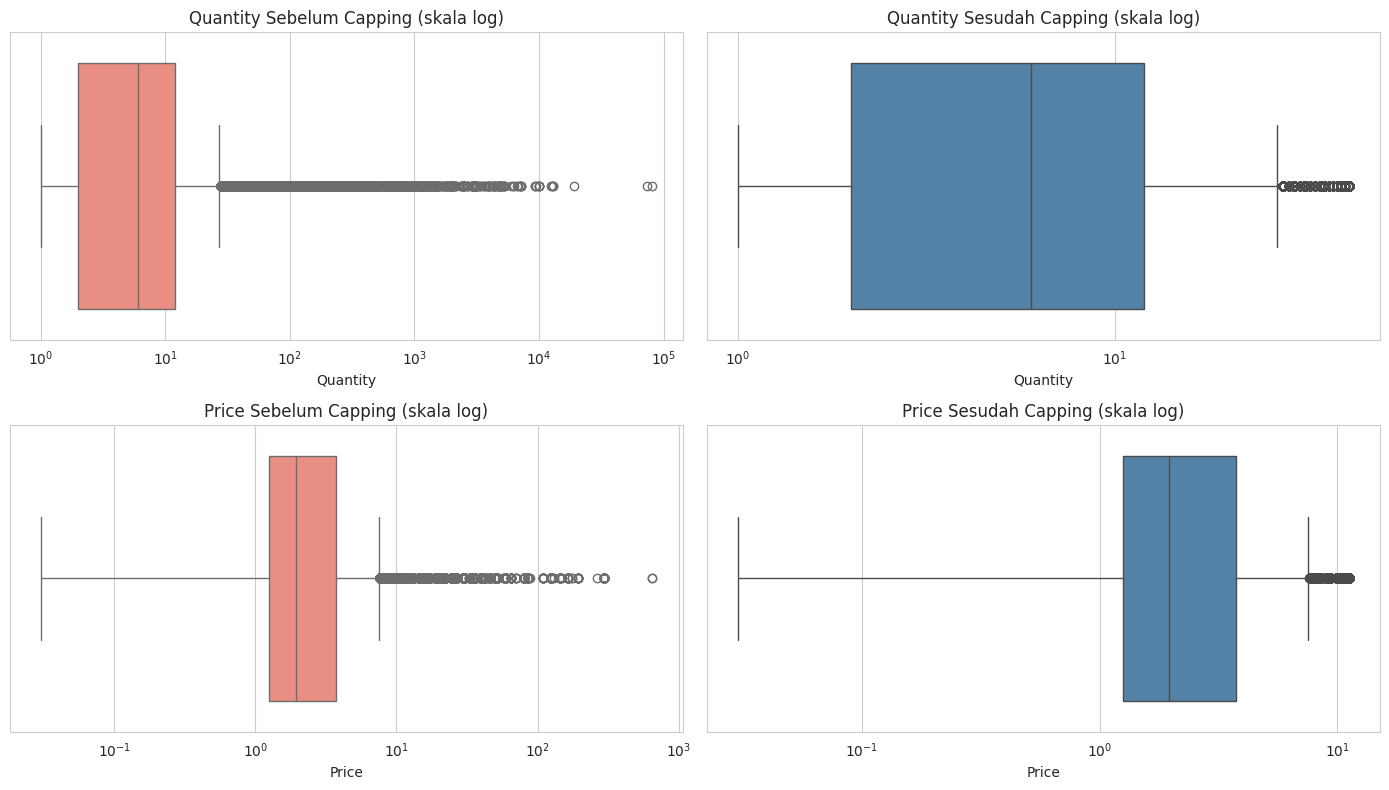

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for row, col in enumerate(["Quantity", "Price"]):
    b = before_cap.loc[before_cap[col] > 0, col]
    a = clean.loc[clean[col] > 0, col]
    sns.boxplot(x=b, ax=axes[row, 0], color="salmon")
    sns.boxplot(x=a, ax=axes[row, 1], color="steelblue")
    axes[row, 0].set(xscale="log", title=f"{col} Sebelum Capping (skala log)")
    axes[row, 1].set(xscale="log", title=f"{col} Sesudah Capping (skala log)")
plt.tight_layout(); plt.show()

### 4.3 Distribusi Sebelum vs Sesudah Capping

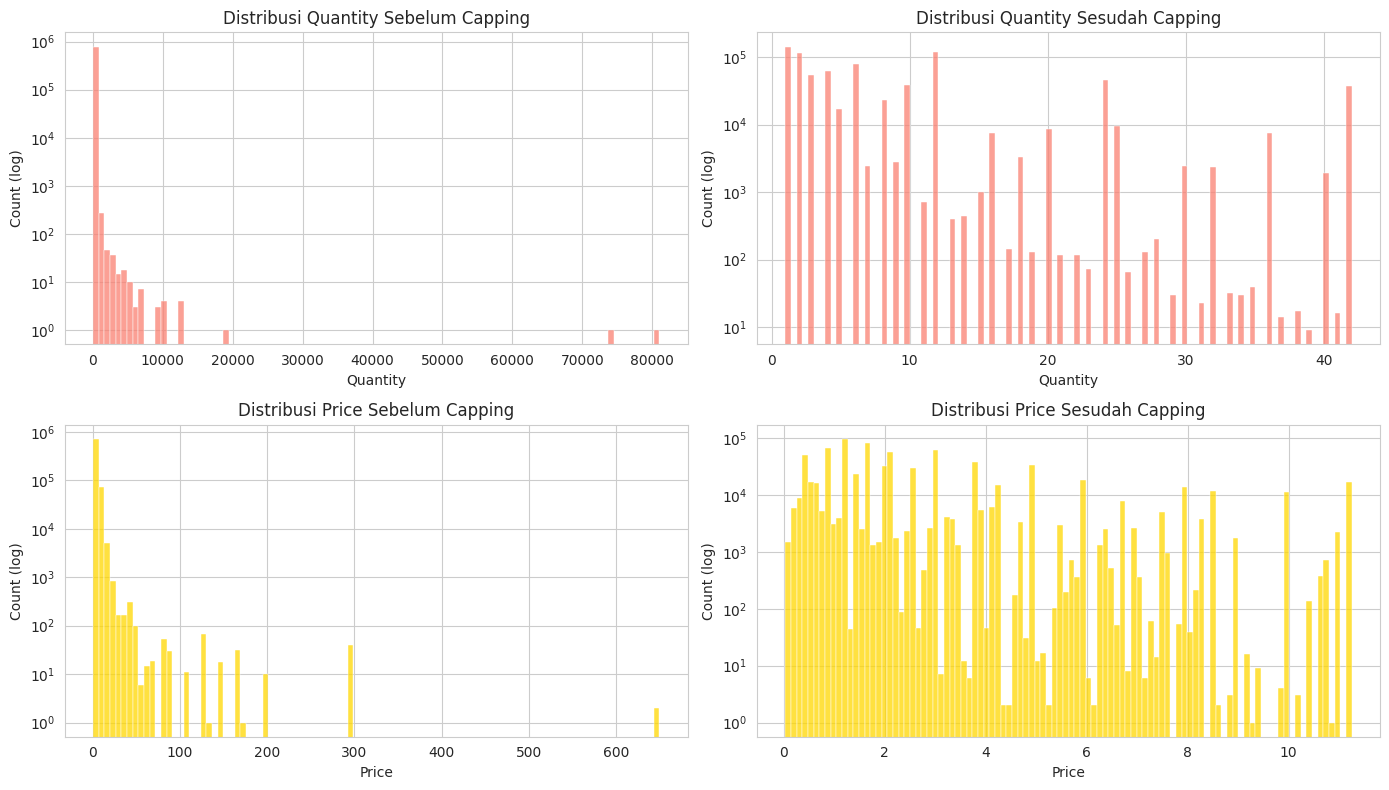

          Batas atas  Di-cap atas
Kolom                            
Quantity       42.00        37269
Price          11.25        18147


In [22]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for row, (col, color) in enumerate([("Quantity", "salmon"), ("Price", "gold")]):
    sns.histplot(before_cap.loc[~before_cap["IsCancelled"], col], bins=100, ax=axes[row, 0], color=color)
    sns.histplot(clean.loc[~clean["IsCancelled"], col], bins=100, ax=axes[row, 1], color=color)
    axes[row, 0].set(yscale="log", ylabel="Count (log)", title=f"Distribusi {col} Sebelum Capping")
    axes[row, 1].set(yscale="log", ylabel="Count (log)", title=f"Distribusi {col} Sesudah Capping")
plt.tight_layout(); plt.show()

print(cap_table[["Batas atas", "Di-cap atas"]].round(2).to_string())

Sebelum capping, sumbu-x ditarik oleh segelintir nilai ekstrem sehingga hampir semua data menumpuk di satu batang. Sesudah capping, bentuk distribusi terlihat jelas. Lonjakan di ujung kanan adalah nilai yang dipangkas ke batas atas.

### 4.4 Tren Revenue Bulanan & Negara dengan Revenue Tertinggi

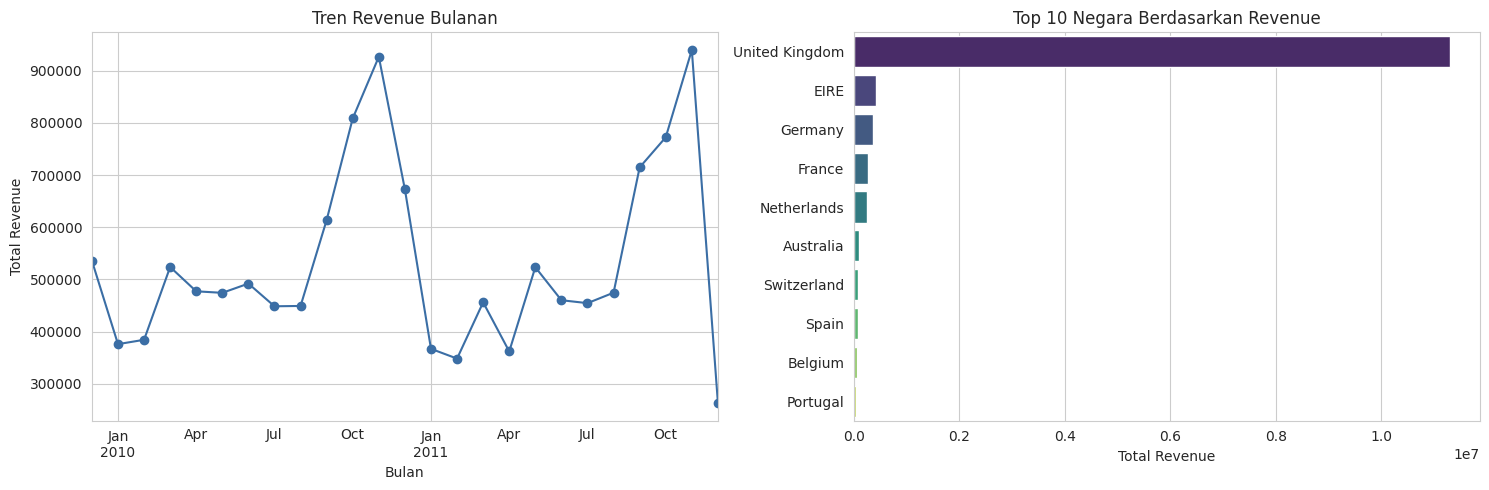

Porsi revenue United Kingdom: 84.9%


In [23]:
purchases = clean[~clean["IsCancelled"]]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

monthly_rev = purchases.set_index("InvoiceDate")["TotalPrice"].resample("ME").sum()
monthly_rev.plot(ax=axes[0], marker="o", color="#3b6ea5")
axes[0].set(title="Tren Revenue Bulanan", xlabel="Bulan", ylabel="Total Revenue")

top_country_rev = purchases.groupby("Country")["TotalPrice"].sum().nlargest(10)
sns.barplot(x=top_country_rev.values, y=top_country_rev.index, hue=top_country_rev.index,
            legend=False, palette="viridis", ax=axes[1])
axes[1].set(title="Top 10 Negara Berdasarkan Revenue", xlabel="Total Revenue", ylabel="")
plt.tight_layout(); plt.show()

print(f"Porsi revenue United Kingdom: {top_country_rev.iloc[0] / purchases['TotalPrice'].sum():.1%}")

Revenue berpola musiman: naik tajam menjelang akhir tahun (September-November, musim belanja hadiah Natal), lalu turun. Bulan Desember 2011 terlihat rendah karena data hanya sampai 9 Desember. United Kingdom mendominasi revenue, sehingga `Country` dikelompokkan menjadi top-10 + `Other`.

### 4.5 Justifikasi Horizon Churn 90 Hari (Selang Waktu Antar-Pembelian)
Dataset tidak punya label churn, sehingga perlu ditentukan berapa hari tanpa belanja yang dianggap "tidak kembali". Dihitung selang hari antar-invoice berurutan untuk pelanggan yang belanja berulang.

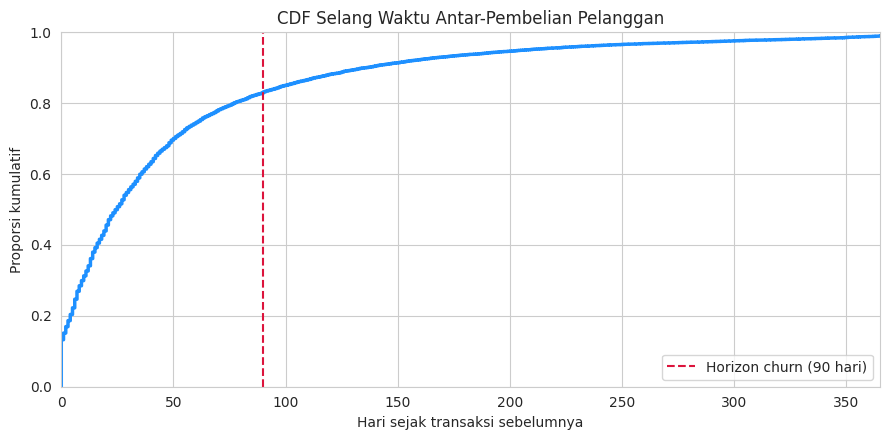

83.2% pembelian berulang terjadi dalam <= 90 hari (median 25 hari).


In [24]:
trips = (purchases.groupby(["Customer ID", "Invoice"])["InvoiceDate"].first()
         .reset_index().sort_values(["Customer ID", "InvoiceDate"]))
intervals = trips.groupby("Customer ID")["InvoiceDate"].diff().dt.days.dropna()

plt.figure(figsize=(9, 4.5))
sns.ecdfplot(intervals, color="dodgerblue", linewidth=2.5)
plt.axvline(CHURN_DAYS, color="crimson", linestyle="--", label=f"Horizon churn ({CHURN_DAYS} hari)")
plt.title("CDF Selang Waktu Antar-Pembelian Pelanggan")
plt.xlabel("Hari sejak transaksi sebelumnya"); plt.ylabel("Proporsi kumulatif")
plt.xlim(0, 365); plt.legend(); plt.tight_layout(); plt.show()

print(f"{(intervals <= CHURN_DAYS).mean():.1%} pembelian berulang terjadi dalam <= {CHURN_DAYS} hari "
      f"(median {intervals.median():.0f} hari).")

Sebagian besar pembelian berulang terjadi dalam 90 hari. Jadi pelanggan yang tidak kembali dalam 90 hari sudah berada di luar kebiasaan belanja normal, dan wajar dianggap **churn**. Angka 90 hari ini yang dipakai sebagai panjang periode label pada Bagian 5.

## OUTPUT 1 - Transaksi Clean
Seluruh transaksi hasil cleaning. Invoice batal **tetap disimpan** dengan penanda `IsCancelled` karena dibutuhkan untuk fitur `ReturnRate`. Dataset lain wajib memfilter `IsCancelled == False` saat menghitung pembelian.

In [25]:
def save(data, name, **kw):
    # simpan CSV ke folder output dan tampilkan ringkasannya
    path = os.path.join(OUTPUT_DIR, name)
    data.to_csv(path, index=kw.pop("index", False), **kw)
    print(f"Tersimpan: {path}  ({data.shape[0]:,} baris x {data.shape[1]} kolom)")


save(clean, "01_transaksi_clean.csv")
pd.Series({
    "Baris transaksi": f"{len(clean):,}",
    "Invoice unik": f"{clean['Invoice'].nunique():,}",
    "Pelanggan unik": f"{clean['Customer ID'].nunique():,}",
    "Produk unik (StockCode)": f"{clean['StockCode'].nunique():,}",
    "Negara": clean["Country"].nunique(),
    "Periode": f"{clean['InvoiceDate'].min():%d %b %Y} s.d. {clean['InvoiceDate'].max():%d %b %Y}",
}, name="Nilai").to_frame()

Tersimpan: /content/drive/MyDrive/KELOMPOK1_SAINSDATA/data/01_transaksi_clean.csv  (808,582 baris x 11 kolom)


,Nilai
Baris transaksi,"808,582"
Invoice unik,"43,876"
Pelanggan unik,"5,875"
Produk unik (StockCode),"4,634"
Negara,41
Periode,01 Dec 2009 s.d. 09 Dec 2011


## 5. Pemotongan Temporal: Menghapus 90 Hari Terakhir
Pada Tugas Akhir III, label dibuat dengan `Churn = Recency > 90`, sehingga label **identik** dengan salah satu fitur (*target leakage*). Sesuai perbaikan pada tugas Seleksi Fitur, data dibagi berdasarkan waktu:

```
awal data ─────────────── CUTOFF (11 Sep 2011) ───────────── akhir data (10 Des 2011)
|  OUTPUT 2: transaksi untuk menghitung fitur  |  90 hari terakhir: hanya untuk label Churn  |
```

- **Fitur** pelanggan dihitung **hanya** dari transaksi sebelum `CUTOFF` (OUTPUT 2).
- **`Churn = 1`** jika pelanggan **tidak membeli sama sekali** dalam 90 hari setelah `CUTOFF`.

Model hanya "melihat" masa lalu dan menebak masa depan, sama seperti kondisi nyata.

In [26]:
END_DATE = clean["InvoiceDate"].max() + pd.Timedelta(days=1)
CUTOFF = END_DATE - pd.Timedelta(days=CHURN_DAYS)

trans_before = clean[clean["InvoiceDate"] < CUTOFF].reset_index(drop=True)   # periode fitur
trans_label = clean[clean["InvoiceDate"] >= CUTOFF].reset_index(drop=True)   # periode label

pd.DataFrame({
    "Periode": [f"{clean['InvoiceDate'].min():%d %b %Y} s.d. sebelum {CUTOFF:%d %b %Y %H:%M}",
                f"{CUTOFF:%d %b %Y %H:%M} s.d. {clean['InvoiceDate'].max():%d %b %Y %H:%M}"],
    "Baris": [len(trans_before), len(trans_label)],
    "Invoice": [trans_before["Invoice"].nunique(), trans_label["Invoice"].nunique()],
    "Pelanggan": [trans_before["Customer ID"].nunique(), trans_label["Customer ID"].nunique()],
}, index=["Periode fitur (OUTPUT 2)", "90 hari terakhir (label)"])

,Periode,Baris,Invoice,Pelanggan
Periode fitur (OUTPUT 2),01 Dec 2009 s.d. sebelum 11 Sep 2011 12:50,647855,36269,5284
90 hari terakhir (label),11 Sep 2011 12:50 s.d. 09 Dec 2011 12:50,160727,7607,2904


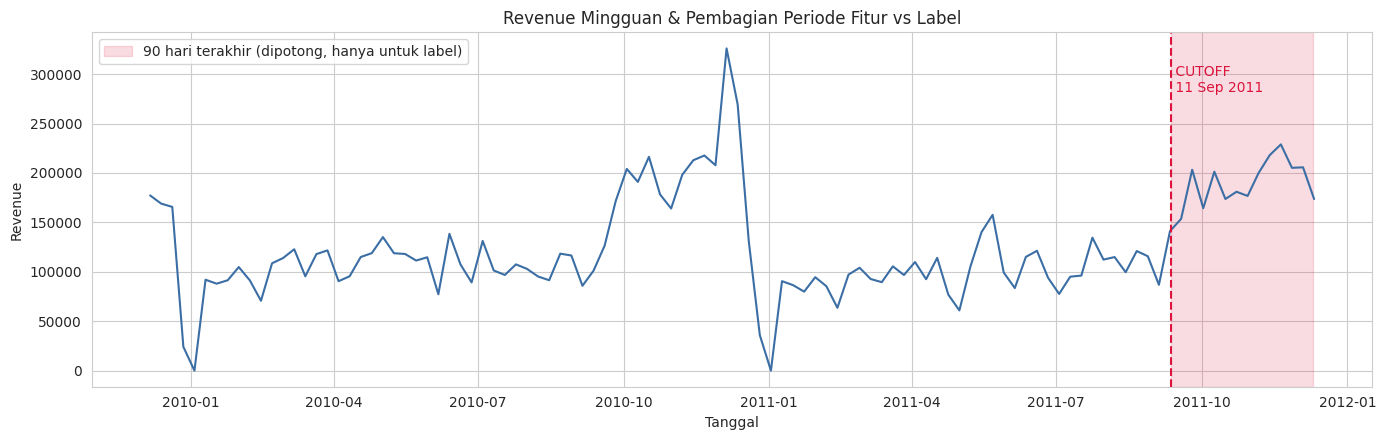

In [27]:
weekly = clean[~clean["IsCancelled"]].set_index("InvoiceDate")["TotalPrice"].resample("W").sum()

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(weekly.index, weekly.values, color="#3b6ea5")
ax.axvspan(CUTOFF, END_DATE, color="crimson", alpha=0.15, label="90 hari terakhir (dipotong, hanya untuk label)")
ax.axvline(CUTOFF, color="crimson", linestyle="--")
ax.text(CUTOFF, weekly.max() * 0.95, f" CUTOFF\n {CUTOFF:%d %b %Y}", color="crimson", va="top")
ax.set(title="Revenue Mingguan & Pembagian Periode Fitur vs Label", xlabel="Tanggal", ylabel="Revenue")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

## OUTPUT 2 - Transaksi Clean tanpa 90 Hari Terakhir
Dataset transaksi yang sama dengan OUTPUT 1, tetapi transaksi pada 90 hari terakhir sudah dihapus. Dataset ini menjadi **satu-satunya sumber fitur** untuk Classification.

In [28]:
assert trans_before["InvoiceDate"].max() < CUTOFF
save(trans_before, "02_transaksi_clean_tanpa_90_hari_terakhir.csv")
print(f"Transaksi terakhir di OUTPUT 2: {trans_before['InvoiceDate'].max()}  (< CUTOFF {CUTOFF})")

Tersimpan: /content/drive/MyDrive/KELOMPOK1_SAINSDATA/data/02_transaksi_clean_tanpa_90_hari_terakhir.csv  (647,855 baris x 11 kolom)
Transaksi terakhir di OUTPUT 2: 2011-09-11 12:46:00  (< CUTOFF 2011-09-11 12:50:00)


## 6. Feature Engineering per Pelanggan
Fungsi yang sama dengan tugas Seleksi Fitur. Semua fitur dihitung dari transaksi **sebelum** `ref_date`:

| Fitur | Definisi |
|---|---|
| `Recency` | Hari sejak pembelian terakhir sampai `ref_date` |
| `Frequency` | Jumlah invoice pembelian unik |
| `Monetary` | Total nilai belanja |
| `AvgBasketValue` | Rata-rata nilai per baris transaksi |
| `UniqueProducts` | Jumlah produk berbeda yang pernah dibeli |
| `TenureDays` | Selisih hari pembelian pertama dan terakhir (rentang aktif) |
| `CustomerAge` | **Umur pelanggan**: hari sejak pembelian **pertama** sampai `ref_date` = `Recency + TenureDays` |
| `RecencyRatio` | `Recency / (rata-rata jarak antar-pembelian + 1)`: seberapa "terlambat" pelanggan dibanding ritme belanjanya sendiri. Pembeli sekali: jarak = `CustomerAge` (ritme belum diketahui, rasio ≈ 1) |
| `ReturnRate` | Invoice batal / seluruh invoice |
| `Country` | Negara dominan (top-10 + `Other`) |

In [29]:
def build_features(df, ref_date):
    # fitur per pelanggan (1 baris = 1 Customer ID) dari transaksi sebelum ref_date
    hist = df[df["InvoiceDate"] < ref_date]
    buy = hist[~hist["IsCancelled"]]                       # pembelian riil saja

    f = buy.groupby("Customer ID").agg(
        Recency=("InvoiceDate", lambda x: (ref_date - x.max()).days),
        Frequency=("Invoice", "nunique"),
        Monetary=("TotalPrice", "sum"),
        AvgBasketValue=("TotalPrice", "mean"),
        UniqueProducts=("StockCode", "nunique"),
        First=("InvoiceDate", "min"), Last=("InvoiceDate", "max"),
    ).reset_index()
    f["TenureDays"] = (f["Last"] - f["First"]).dt.days
    f["CustomerAge"] = f["Recency"] + f["TenureDays"]                 # hari sejak pembelian pertama
    avg_interval = np.where(f["Frequency"] > 1,
                            f["TenureDays"] / (f["Frequency"] - 1).clip(lower=1),
                            f["CustomerAge"])                          # pembeli sekali: ritme belum diketahui
    f["RecencyRatio"] = f["Recency"] / (avg_interval + 1)

    cancel = hist[hist["IsCancelled"]].groupby("Customer ID")["Invoice"].nunique()
    total = hist.groupby("Customer ID")["Invoice"].nunique()
    f["ReturnRate"] = f["Customer ID"].map((cancel / total).fillna(0)).fillna(0.0)

    dom = hist.groupby("Customer ID")["Country"].agg(lambda s: s.value_counts().idxmax())
    f["Country"] = f["Customer ID"].map(dom)
    top = f["Country"].value_counts().nlargest(TOP_N_COUNTRIES).index
    f["Country"] = f["Country"].where(f["Country"].isin(top), "Other")
    return f.drop(columns=["First", "Last"])

Catatan: fitur yang dibuang pada tugas Seleksi Fitur (`TotalItemsBought` dan 5 fitur *time-window*) tidak dibuat lagi di sini karena terbukti redundan.

**Kenapa `CustomerAge`, bukan `TenureDays` langsung?** `TenureDays` bernilai 0 untuk semua pembeli sekali, baik yang **baru datang** kemarin maupun yang **sudah pergi** setahun lalu, sehingga keduanya tetap tidak bisa dibedakan (diuji: pelanggan baru yang masuk cluster HILANG justru naik dari 84 menjadi 132). `CustomerAge = Recency + TenureDays` kecil untuk pelanggan baru dan besar untuk pelanggan lama, sehingga bisa memisahkan keduanya.

## 7A. Dataset Classification (Prediksi Churn)
### 7A.1 Membentuk fitur & label

In [30]:
cls = build_features(trans_before, CUTOFF)                  # fitur dari OUTPUT 2
buyers_after = trans_label.loc[~trans_label["IsCancelled"], "Customer ID"].unique()
cls["Churn"] = (~cls["Customer ID"].isin(buyers_after)).astype(int)

print(f"Pelanggan (punya riwayat sebelum cutoff): {len(cls):,}")
print(f"Churn = 1 : {cls['Churn'].sum():,} ({cls['Churn'].mean():.1%})")
print(f"Churn = 0 : {(cls['Churn'] == 0).sum():,} ({1 - cls['Churn'].mean():.1%})")
cls.head()

Pelanggan (punya riwayat sebelum cutoff): 5,260
Churn = 1 : 2,976 (56.6%)
Churn = 0 : 2,284 (43.4%)


,Customer ID,Recency,Frequency,Monetary,AvgBasketValue,UniqueProducts,TenureDays,CustomerAge,RecencyRatio,ReturnRate,Country,Churn
0,12346,236,3,213.04,8.521600,25,321,557,1.461300,0.250000,United Kingdom,1
1,12347,40,6,3890.26,19.950051,107,274,314,0.716846,0.000000,Other,0
2,12348,159,4,828.38,18.826818,24,189,348,2.484375,0.000000,Other,0
3,12349,318,2,2103.54,21.035400,89,181,499,1.747253,0.333333,Other,0
4,12350,220,1,294.40,18.400000,16,0,220,0.995475,0.000000,Other,1


**Cek leakage.** Bila label masih bocor, semua pelanggan dengan `Recency > 90` pasti churn dan sebaliknya.

In [31]:
pd.crosstab(cls["Recency"] > CHURN_DAYS, cls["Churn"], rownames=["Recency > 90"], margins=True)

Churn,0,1,All
Recency > 90,,,
False,1315,596,1911
True,969,2380,3349
All,2284,2976,5260


Ada pelanggan dengan `Recency` kecil yang tetap churn, dan pelanggan dengan `Recency` besar yang ternyata kembali. Jadi `Recency` hanya **petunjuk**, bukan penentu label, dan sah dipakai sebagai fitur.

### 7A.2 Cek noise & visualisasi pada level pelanggan

In [32]:
X_cls = cls[FEATURES_CLASSIFICATION]
pd.DataFrame({
    "Missing": X_cls.isna().sum(),
    "Nilai <= 0": (X_cls <= 0).sum(),
    "Min": X_cls.min(), "Median": X_cls.median(), "Max": X_cls.max(),
    "Skewness": X_cls.skew(),
}).round(2)

,Missing,Nilai <= 0,Min,Median,Max,Skewness
Recency,0,30,0.00,163.00,649.00,0.67
Frequency,0,0,1.00,3.00,284.00,10.48
Monetary,0,0,1.55,725.94,199186.83,16.97
CustomerAge,0,4,0.00,474.00,649.00,-0.63
RecencyRatio,0,30,0.00,1.00,648.00,9.86


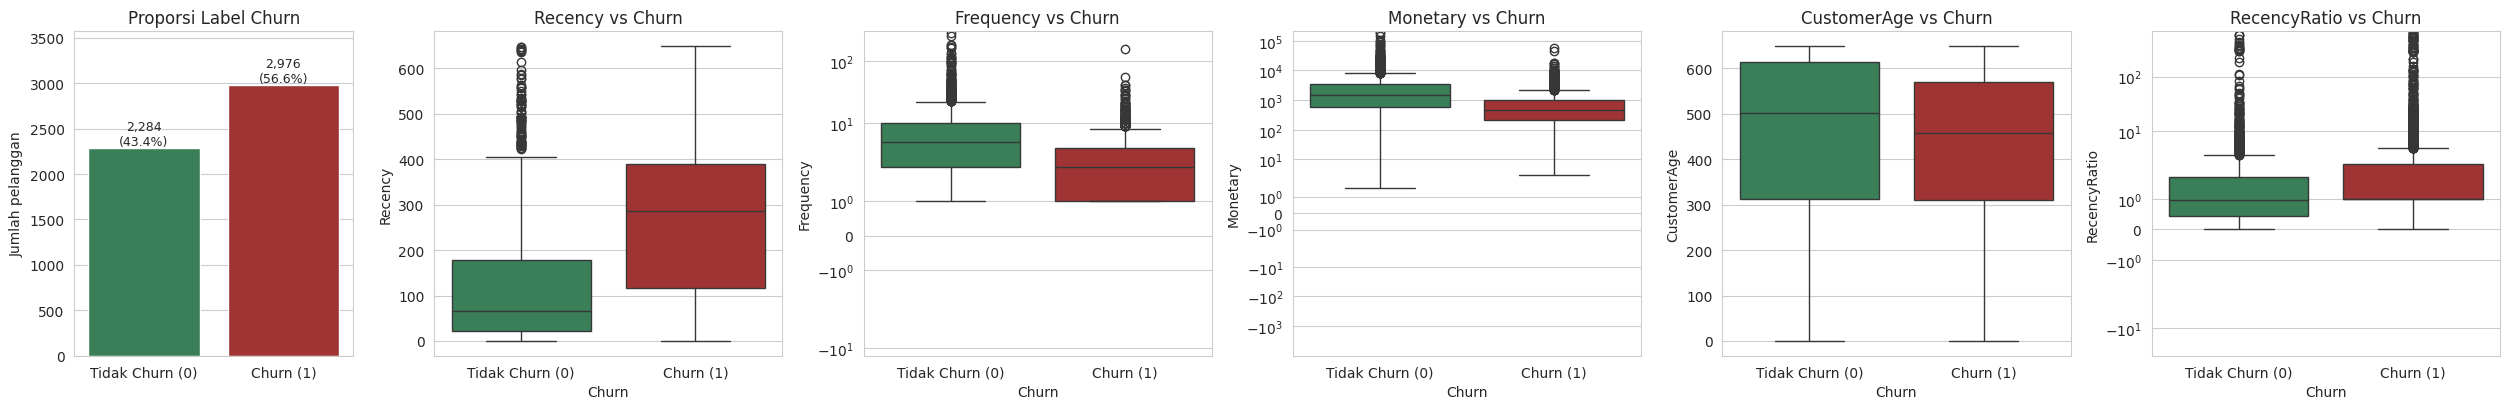

In [33]:
n = len(FEATURES_CLASSIFICATION)
fig, axes = plt.subplots(1, n + 1, figsize=(4.2 * (n + 1), 4.2), gridspec_kw={"width_ratios": [0.8] + [1] * n})

counts = cls["Churn"].value_counts().sort_index()
sns.barplot(x=["Tidak Churn (0)", "Churn (1)"], y=counts.values, hue=["Tidak Churn (0)", "Churn (1)"],
            legend=False, palette=["seagreen", "firebrick"], ax=axes[0])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}\n({v / counts.sum():.1%})", ha="center", va="bottom", fontsize=9)
axes[0].set(title="Proporsi Label Churn", ylabel="Jumlah pelanggan", ylim=(0, counts.max() * 1.2))

for ax, feat in zip(axes[1:], FEATURES_CLASSIFICATION):
    sns.boxplot(x="Churn", y=feat, data=cls, hue="Churn", legend=False,
                palette={0: "seagreen", 1: "firebrick"}, ax=ax)
    ax.set_xticks([0, 1], ["Tidak Churn (0)", "Churn (1)"])
    ax.set_title(f"{feat} vs Churn")
    if feat not in ("Recency", "CustomerAge"):
        ax.set_yscale("symlog")
plt.tight_layout(); plt.show()

- Label cukup **seimbang** (tidak perlu *oversampling*), tetapi tetap dipakai `stratify` saat membagi data.
- Pelanggan churn cenderung punya `Recency` dan `RecencyRatio` lebih besar (sudah "terlambat" dibanding ritme belanjanya), serta `Frequency` dan `Monetary` lebih kecil, sehingga fitur-fitur ini punya daya pembeda.

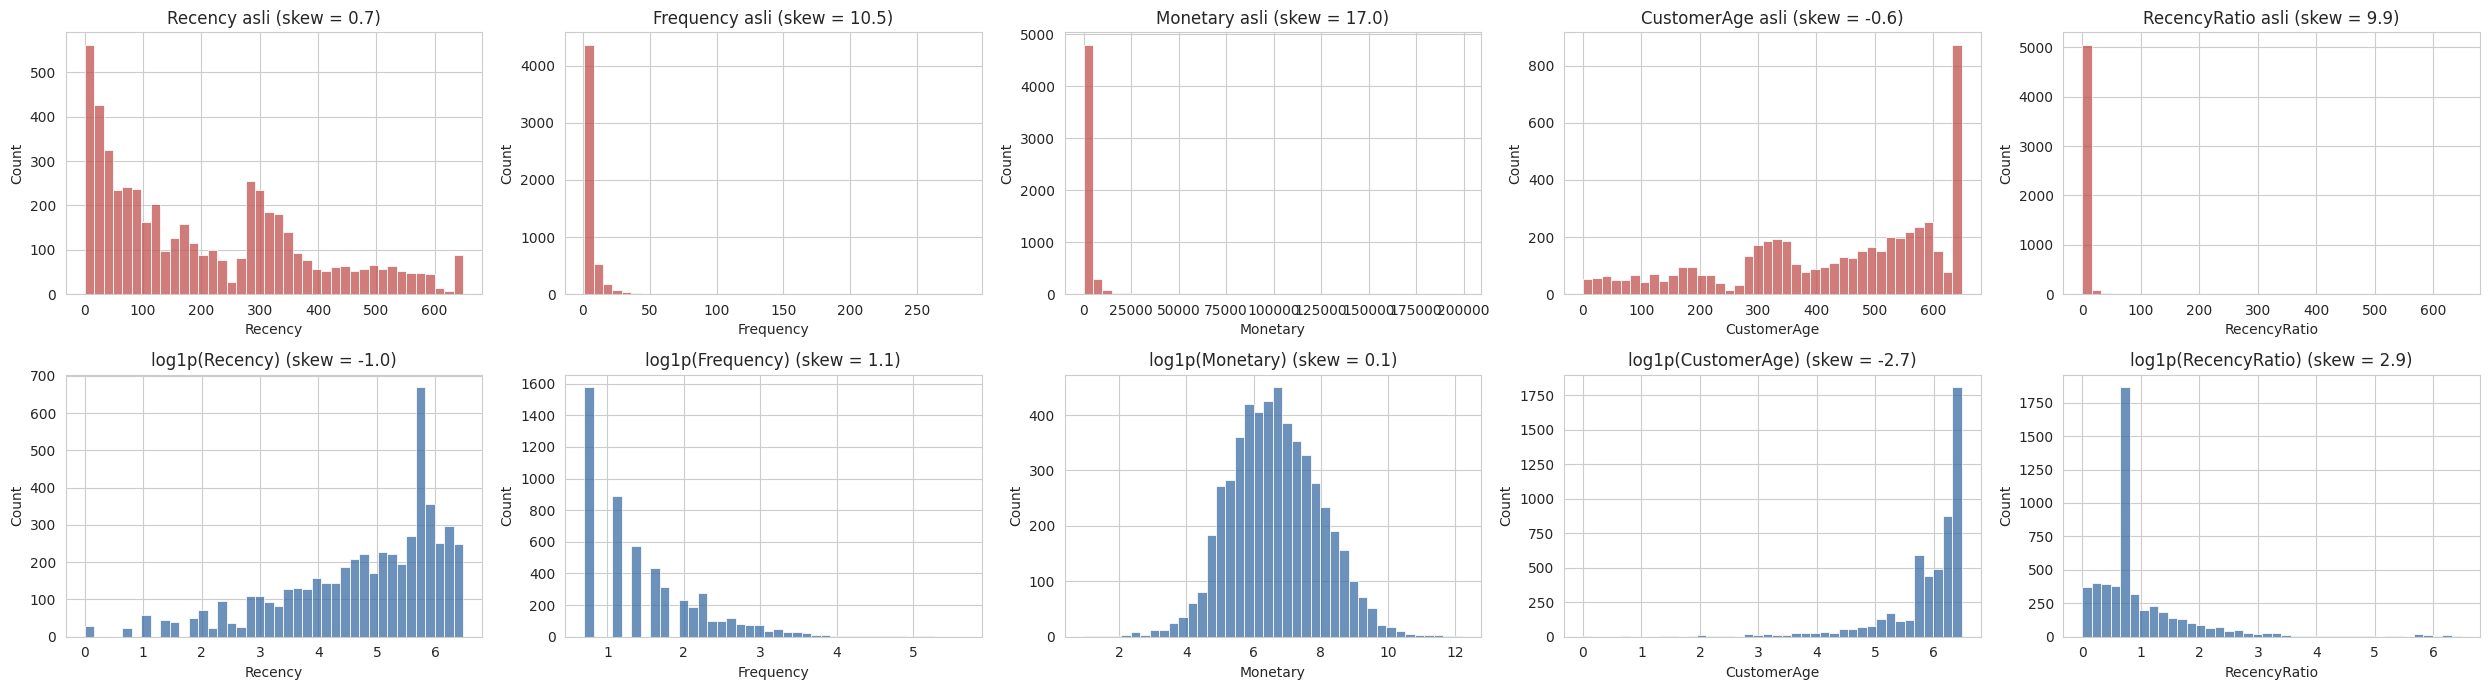

In [34]:
fig, axes = plt.subplots(2, len(FEATURES_CLASSIFICATION), figsize=(5 * len(FEATURES_CLASSIFICATION), 7))
for j, feat in enumerate(FEATURES_CLASSIFICATION):
    sns.histplot(cls[feat], bins=40, ax=axes[0, j], color="#c0504d")
    axes[0, j].set_title(f"{feat} asli (skew = {cls[feat].skew():.1f})")
    sns.histplot(np.log1p(cls[feat]), bins=40, ax=axes[1, j], color="#3b6ea5")
    axes[1, j].set_title(f"log1p({feat}) (skew = {np.log1p(cls[feat]).skew():.1f})")
plt.tight_layout(); plt.show()

Distribusi `Frequency`, `Monetary`, dan `RecencyRatio` sangat miring ke kanan (segelintir pelanggan grosir). Transformasi `log1p` membuat distribusinya jauh lebih simetris, sehingga cocok untuk model berbasis jarak/linear. Pelanggan ekstrem **tidak dibuang** karena mereka pelanggan nyata yang penting bagi bisnis.

### 7A.3 Split train/test & scaling
- Data dibagi **75 % train / 25 % test** dengan `stratify=Churn` (sama dengan tugas Seleksi Fitur).
- Versi **scaled**: `log1p` → `StandardScaler`. Scaler **di-fit hanya pada data train** lalu diterapkan ke test, agar informasi data uji tidak bocor ke data latih.
- Versi **tanpa scaling** untuk model berbasis tree (Decision Tree, Random Forest), yang tidak terpengaruh skala.

In [35]:
idx_train, idx_test = train_test_split(cls.index, test_size=TEST_SIZE, stratify=cls["Churn"],
                                       random_state=RANDOM_STATE)

cls_ready = cls[["Customer ID"] + FEATURES_CLASSIFICATION + ["Churn"]].copy()
cls_ready["Split"] = "train"
cls_ready.loc[idx_test, "Split"] = "test"

scaler_cls = StandardScaler().fit(np.log1p(cls_ready.loc[idx_train, FEATURES_CLASSIFICATION]))
cls_ready_scaled = cls_ready.copy()
cls_ready_scaled[FEATURES_CLASSIFICATION] = scaler_cls.transform(np.log1p(cls_ready[FEATURES_CLASSIFICATION]))

cls_ready.groupby("Split")["Churn"].agg(Jumlah="size", Proporsi_Churn="mean").round(3)

,Jumlah,Proporsi_Churn
Split,,
test,1315,0.566
train,3945,0.566


## OUTPUT 3 - Dataset Siap Classification

In [36]:
save(cls_ready, "03_classification_ready.csv")
save(cls_ready_scaled, "03_classification_ready_scaled.csv")
print("\nStatistik versi scaled (train): mean ~ 0, std ~ 1")
display(cls_ready_scaled[cls_ready_scaled["Split"] == "train"][FEATURES_CLASSIFICATION].describe().loc[["mean", "std"]].round(3))
cls_ready_scaled.head()

Tersimpan: /content/drive/MyDrive/KELOMPOK1_SAINSDATA/data/03_classification_ready.csv  (5,260 baris x 8 kolom)
Tersimpan: /content/drive/MyDrive/KELOMPOK1_SAINSDATA/data/03_classification_ready_scaled.csv  (5,260 baris x 8 kolom)

Statistik versi scaled (train): mean ~ 0, std ~ 1


,Recency,Frequency,Monetary,CustomerAge,RecencyRatio
mean,-0.0,0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0


,Customer ID,Recency,Frequency,Monetary,CustomerAge,RecencyRatio,Churn,Split
0,12346,0.537787,-0.129912,-0.935861,0.559233,-0.078885,1,train
1,12347,-0.748582,0.583759,1.204792,-0.186210,-0.475924,0,train
2,12348,0.249727,0.154660,0.063871,-0.052581,0.304263,0,test
3,12349,0.755639,-0.496790,0.751145,0.416150,0.042267,0,train
4,12350,0.486539,-1.013875,-0.698078,-0.648258,-0.310150,1,train


Cara pakai saat modeling:
```python
df = pd.read_csv(BASE / "data" / "03_classification_ready_scaled.csv")   # atau versi tanpa scaling untuk tree
train, test = df[df.Split == "train"], df[df.Split == "test"]
F = ["Recency", "Frequency", "Monetary", "CustomerAge", "RecencyRatio"]
X_train, y_train = train[F], train["Churn"]
X_test,  y_test  = test[F],  test["Churn"]
```

## 7B. Dataset Clustering (Segmentasi Pelanggan)
Clustering tidak memiliki label, sehingga fitur dihitung dari **seluruh periode** (OUTPUT 1) dengan `ref_date` = 1 hari setelah transaksi terakhir.

In [37]:
clu = build_features(clean, END_DATE)
print(f"Pelanggan: {len(clu):,}")
X_clu = clu[FEATURES_CLUSTERING]
pd.DataFrame({
    "Missing": X_clu.isna().sum(),
    "Nilai <= 0": (X_clu <= 0).sum(),
    "Min": X_clu.min(), "Median": X_clu.median(), "Max": X_clu.max(),
    "Skewness": X_clu.skew(),
}).round(2)

Pelanggan: 5,852


,Missing,Nilai <= 0,Min,Median,Max,Skewness
Recency,0,0,1.00,95.00,739.00,0.89
Frequency,0,0,1.00,3.00,373.00,12.04
Monetary,0,0,2.95,808.70,255493.17,18.60
AvgBasketValue,0,0,2.04,16.67,459.90,6.87
UniqueProducts,0,0,1.00,45.00,2546.00,6.22
CustomerAge,0,0,1.00,529.00,739.00,-0.62


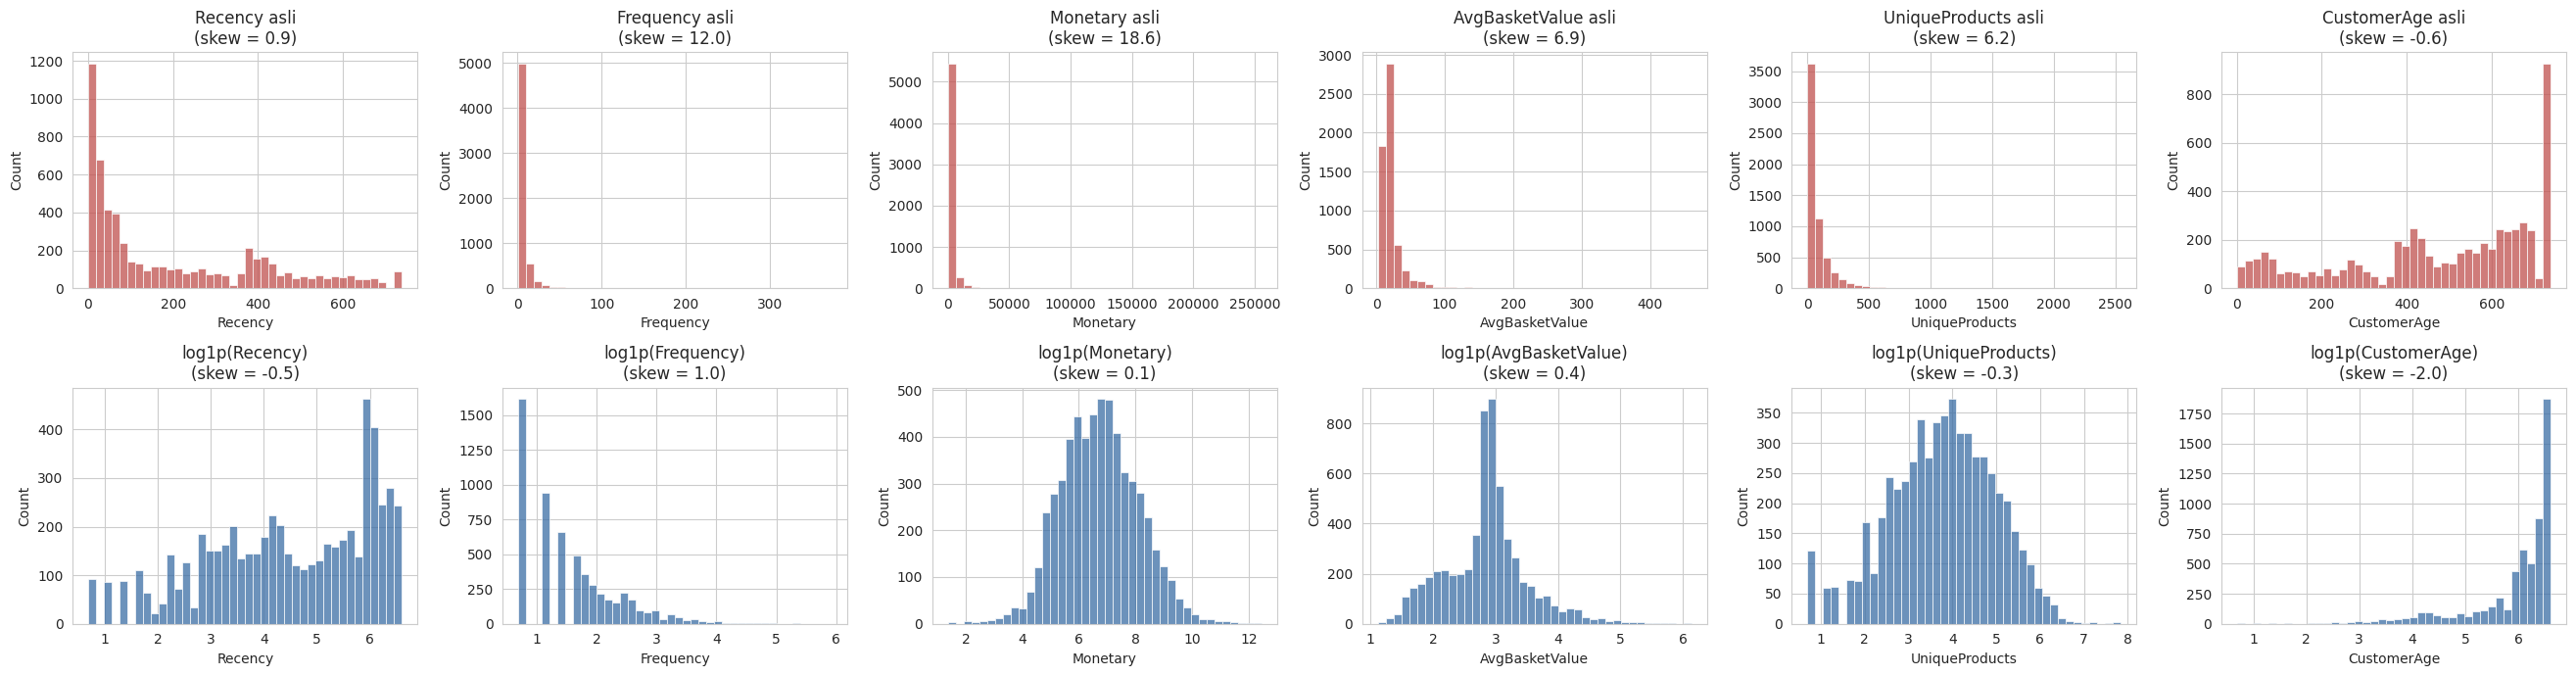

In [38]:
fig, axes = plt.subplots(2, len(FEATURES_CLUSTERING), figsize=(4.4 * len(FEATURES_CLUSTERING), 7))
for j, feat in enumerate(FEATURES_CLUSTERING):
    sns.histplot(clu[feat], bins=40, ax=axes[0, j], color="#c0504d")
    axes[0, j].set_title(f"{feat} asli\n(skew = {clu[feat].skew():.1f})")
    sns.histplot(np.log1p(clu[feat]), bins=40, ax=axes[1, j], color="#3b6ea5")
    axes[1, j].set_title(f"log1p({feat})\n(skew = {np.log1p(clu[feat]).skew():.1f})")
plt.tight_layout(); plt.show()

K-Means memakai jarak Euclidean, sehingga sangat sensitif terhadap skala dan nilai ekstrem. Tanpa `log1p`, tugas Seleksi Fitur menunjukkan K-Means membentuk satu cluster yang hanya berisi ± 14 pelanggan ekstrem. Karena itu fitur di-`log1p` lalu di-standardisasi.

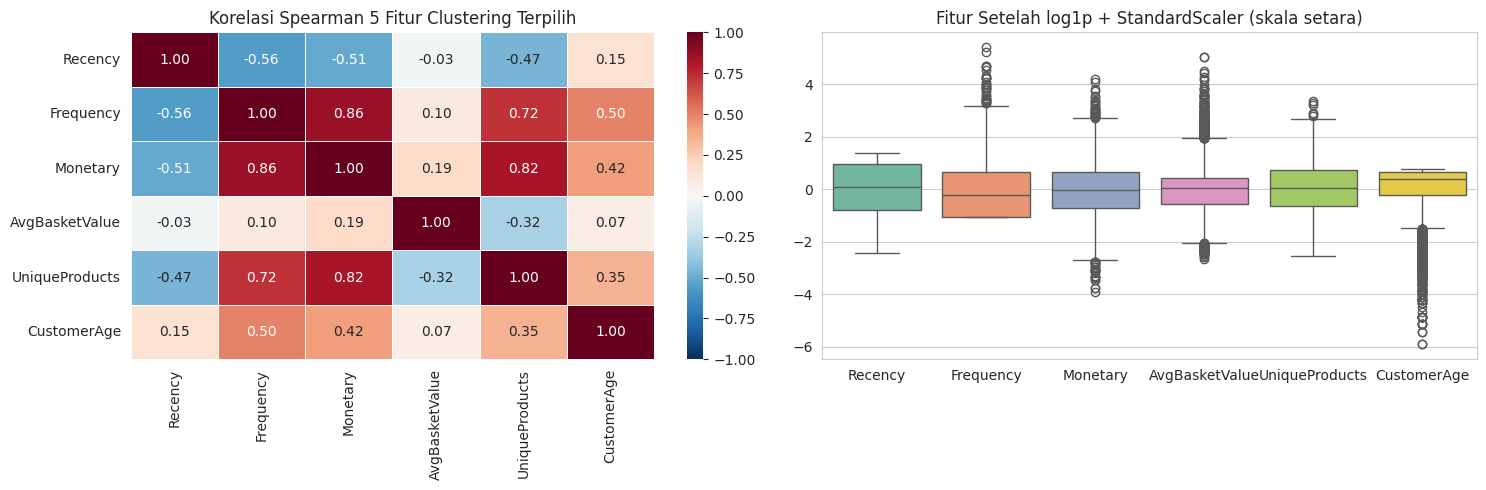

In [39]:
clu_ready_scaled = clu[["Customer ID"]].copy()
clu_ready_scaled[FEATURES_CLUSTERING] = StandardScaler().fit_transform(np.log1p(clu[FEATURES_CLUSTERING]))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(clu[FEATURES_CLUSTERING].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, linewidths=0.5, ax=axes[0])
axes[0].set_title("Korelasi Spearman 5 Fitur Clustering Terpilih")
sns.boxplot(data=clu_ready_scaled[FEATURES_CLUSTERING], ax=axes[1], palette="Set2")
axes[1].set_title("Fitur Setelah log1p + StandardScaler (skala setara)")
plt.tight_layout(); plt.show()

Korelasi tertinggi ada pada `Frequency`–`Monetary` (ρ ≈ 0,86). Keduanya tetap dipakai karena merupakan inti RFM, dan pada tugas Seleksi Fitur subset 5 fitur RFM+ memberi Davies-Bouldin terbaik. `CustomerAge` berkorelasi dengan `Recency` tetapi membawa informasi baru: kapan pelanggan **mulai** belanja. `AvgBasketValue` hampir tidak berkorelasi dengan fitur lain, sehingga menambah informasi baru. Setelah scaling, semua fitur berada pada skala yang sama sehingga tidak ada fitur yang mendominasi jarak.

## OUTPUT 4 - Dataset Siap Clustering
- `04_clustering_ready_scaled.csv`: input K-Means (6 fitur, `log1p` + standardisasi).
- `04_clustering_profil.csv`: nilai asli + `TenureDays`, `ReturnRate`, `Country` untuk menafsirkan cluster (digabung lewat `Customer ID`).

In [40]:
clu_profile = clu[["Customer ID"] + FEATURES_CLUSTERING + PROFILE_CLUSTERING]
assert (clu_ready_scaled["Customer ID"].values == clu_profile["Customer ID"].values).all()

save(clu_ready_scaled, "04_clustering_ready_scaled.csv")
save(clu_profile, "04_clustering_profil.csv")
clu_ready_scaled.head()

Tersimpan: /content/drive/MyDrive/KELOMPOK1_SAINSDATA/data/04_clustering_ready_scaled.csv  (5,852 baris x 7 kolom)
Tersimpan: /content/drive/MyDrive/KELOMPOK1_SAINSDATA/data/04_clustering_profil.csv  (5,852 baris x 10 kolom)


,Customer ID,Recency,Frequency,Monetary,AvgBasketValue,UniqueProducts,CustomerAge
0,12346,0.860933,-0.199156,-0.987972,-0.899551,-0.423534,0.619473
1,12347,-2.150170,0.804865,1.370625,0.404065,0.890343,0.089093
2,12348,-0.075659,0.302855,0.089410,0.332933,-0.456024,0.177487
3,12349,-0.932519,-0.199156,1.057345,0.341612,0.959153,0.513660
4,12350,0.828734,-1.057348,-0.752447,0.190488,-0.775496,-0.208927


## 8. Dataset Association Rules (Market Basket)
Association Rules bekerja pada **level transaksi**: 1 baris = 1 invoice, 1 kolom = 1 produk, nilai `True` bila produk ada di invoice tersebut.

Langkah:
1. Ambil pembelian riil saja (bukan invoice batal, `Quantity > 0`) dari OUTPUT 1.
2. Buang produk langka (< `MIN_ITEM_FREQ_FOR_BASKET` = 50 kemunculan): *support*-nya terlalu kecil sehingga rule yang muncul hanya kebetulan, dan membuat matriks sangat lebar.
3. Pivot menjadi matriks one-hot Invoice × Produk.

Produk unik sebelum filter : 5,229
Produk dipertahankan (>= 50): 2,765 (52.9%)
Baris transaksi dipertahankan: 747,870 dari 790,704 (94.6%)


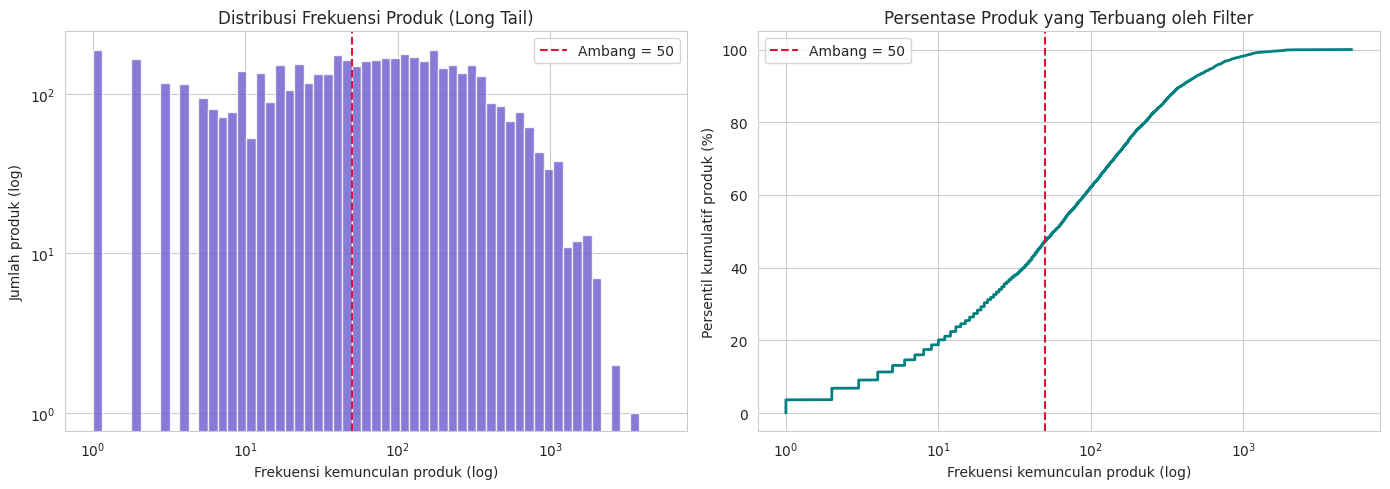

In [41]:
basket_src = clean[(~clean["IsCancelled"]) & (clean["Quantity"] > 0)]
if BASKET_COUNTRY:
    basket_src = basket_src[basket_src["Country"] == BASKET_COUNTRY]

item_freq = basket_src["Description"].value_counts()
kept_items = item_freq[item_freq >= MIN_ITEM_FREQ_FOR_BASKET].index

print(f"Produk unik sebelum filter : {len(item_freq):,}")
print(f"Produk dipertahankan (>= {MIN_ITEM_FREQ_FOR_BASKET}): {len(kept_items):,} ({len(kept_items) / len(item_freq):.1%})")
print(f"Baris transaksi dipertahankan: {item_freq[kept_items].sum():,} dari {item_freq.sum():,} "
      f"({item_freq[kept_items].sum() / item_freq.sum():.1%})")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(item_freq.values, bins=np.logspace(0, np.log10(item_freq.max()), 60), color="slateblue", alpha=0.8)
axes[0].axvline(MIN_ITEM_FREQ_FOR_BASKET, color="crimson", linestyle="--", label=f"Ambang = {MIN_ITEM_FREQ_FOR_BASKET}")
axes[0].set(xscale="log", yscale="log", title="Distribusi Frekuensi Produk (Long Tail)",
            xlabel="Frekuensi kemunculan produk (log)", ylabel="Jumlah produk (log)")
axes[0].legend()

sorted_freq = item_freq.sort_values()
axes[1].plot(sorted_freq.values, np.arange(1, len(sorted_freq) + 1) / len(sorted_freq) * 100, color="teal", lw=2)
axes[1].axvline(MIN_ITEM_FREQ_FOR_BASKET, color="crimson", linestyle="--", label=f"Ambang = {MIN_ITEM_FREQ_FOR_BASKET}")
axes[1].set(xscale="log", title="Persentase Produk yang Terbuang oleh Filter",
            xlabel="Frekuensi kemunculan produk (log)", ylabel="Persentil kumulatif produk (%)")
axes[1].legend()
plt.tight_layout(); plt.show()

Hampir separuh produk dibuang, tetapi sebagian besar volume transaksi tetap dipertahankan. Artinya yang dibuang hanya *long tail* produk langka.

Matriks basket: 36,280 invoice x 2,765 produk
Kepadatan (sel bernilai True): 0.72%


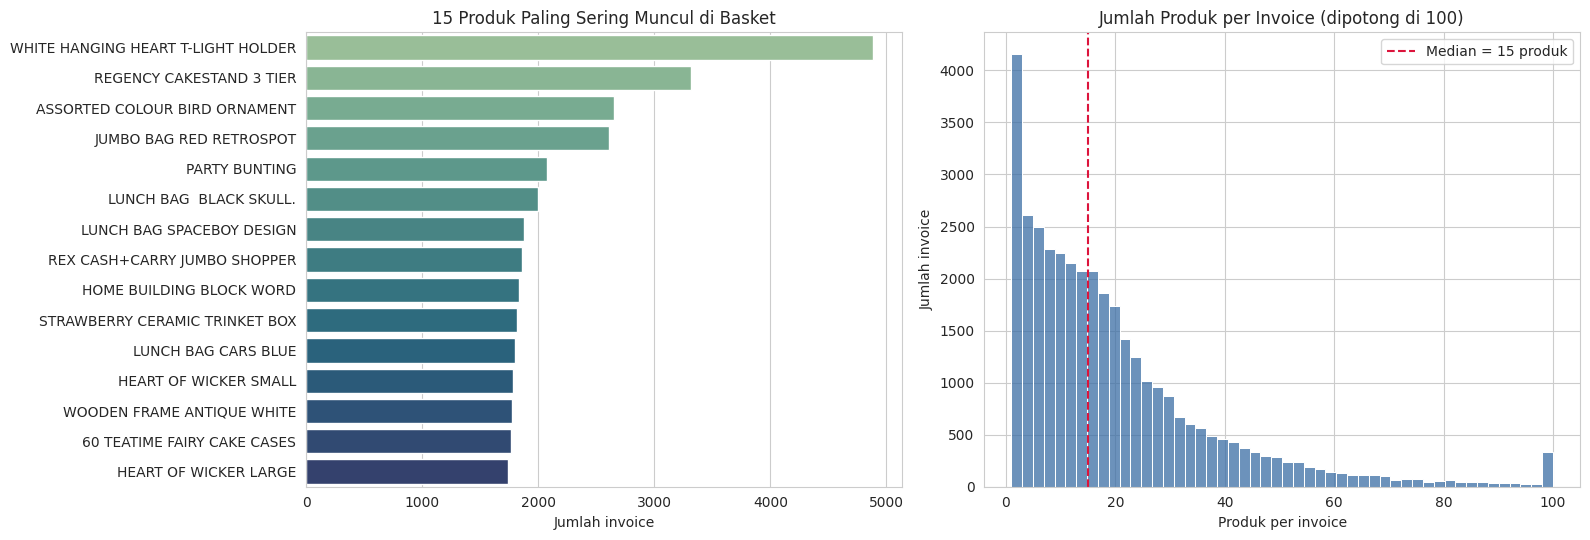

In [42]:
basket_long = basket_src[basket_src["Description"].isin(kept_items)][["Invoice", "Description"]].drop_duplicates()
basket = pd.crosstab(basket_long["Invoice"], basket_long["Description"]).astype(bool)

print(f"Matriks basket: {basket.shape[0]:,} invoice x {basket.shape[1]:,} produk")
print(f"Kepadatan (sel bernilai True): {basket.values.mean():.2%}")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
top_products = basket.sum().nlargest(15)
sns.barplot(x=top_products.values, y=top_products.index, hue=top_products.index, legend=False,
            palette="crest", ax=axes[0])
axes[0].set(title="15 Produk Paling Sering Muncul di Basket", xlabel="Jumlah invoice", ylabel="")

basket_size = basket.sum(axis=1)
sns.histplot(basket_size.clip(upper=100), bins=50, color="#3b6ea5", ax=axes[1])
axes[1].axvline(basket_size.median(), color="crimson", linestyle="--", label=f"Median = {basket_size.median():.0f} produk")
axes[1].set(title="Jumlah Produk per Invoice (dipotong di 100)", xlabel="Produk per invoice", ylabel="Jumlah invoice")
axes[1].legend()
plt.tight_layout(); plt.show()

## OUTPUT 5 - Dataset Siap Association Rules
- `05_association_basket_onehot.pkl`: matriks one-hot (bool) yang langsung bisa masuk `mlxtend.frequent_patterns.apriori/fpgrowth`.
- `05_association_transaksi.csv`: format panjang (Invoice, Description), lebih ringan dan bisa di-pivot ulang.
- `05_association_daftar_produk.csv`: daftar produk + jumlah invoice yang memuatnya (*support* tiap produk).

In [43]:
assert basket.dtypes.eq(bool).all() and basket.index.is_unique

basket.to_pickle(os.path.join(OUTPUT_DIR, "05_association_basket_onehot.pkl"))
print(f"Tersimpan: {OUTPUT_DIR}/05_association_basket_onehot.pkl  ({basket.shape[0]:,} x {basket.shape[1]:,})")
save(basket_long, "05_association_transaksi.csv")
product_list = basket.sum().rename("JumlahInvoice").to_frame()
product_list["Support"] = product_list["JumlahInvoice"] / len(basket)
save(product_list.sort_values("JumlahInvoice", ascending=False).rename_axis("Description").reset_index(),
     "05_association_daftar_produk.csv")
basket.iloc[:5, :8]

Tersimpan: /content/drive/MyDrive/KELOMPOK1_SAINSDATA/data/05_association_basket_onehot.pkl  (36,280 x 2,765)
Tersimpan: /content/drive/MyDrive/KELOMPOK1_SAINSDATA/data/05_association_transaksi.csv  (723,650 baris x 2 kolom)
Tersimpan: /content/drive/MyDrive/KELOMPOK1_SAINSDATA/data/05_association_daftar_produk.csv  (2,765 baris x 3 kolom)


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 MINI TOADSTOOL PEGS,12 PENCIL SMALL TUBE WOODLAND
Invoice,,,,,,,,
489434,False,False,False,False,False,False,False,False
489435,False,False,False,False,False,False,False,False
489436,False,False,False,False,False,False,False,False
489437,False,False,False,False,False,False,False,False
489438,False,False,False,False,False,False,False,False


Cara pakai saat modeling:
```python
from mlxtend.frequent_patterns import fpgrowth, association_rules
basket = pd.read_pickle(BASE / "data" / "05_association_basket_onehot.pkl")
itemsets = fpgrowth(basket, min_support=0.02, use_colnames=True)
rules = association_rules(itemsets, metric="lift", min_threshold=1)
```

## 9. Ringkasan Output

In [44]:
summary = pd.DataFrame([
    ("1", "01_transaksi_clean.csv", clean, "Transaksi (seluruh periode)", "Sumber semua dataset"),
    ("2", "02_transaksi_clean_tanpa_90_hari_terakhir.csv", trans_before, "Transaksi sebelum cutoff", "Sumber fitur Classification"),
    ("3", "03_classification_ready.csv", cls_ready, "Pelanggan", "Classification (tree)"),
    ("3", "03_classification_ready_scaled.csv", cls_ready_scaled, "Pelanggan", "Classification (linear/jarak)"),
    ("4", "04_clustering_ready_scaled.csv", clu_ready_scaled, "Pelanggan", "Clustering (K-Means)"),
    ("4", "04_clustering_profil.csv", clu_profile, "Pelanggan", "Profil cluster"),
    ("5", "05_association_basket_onehot.pkl", basket, "Invoice", "Association Rules"),
    ("5", "05_association_transaksi.csv", basket_long, "Invoice-Produk", "Association Rules (format panjang)"),
], columns=["Output", "File", "data", "Level baris", "Dipakai untuk"])
summary["Baris"] = summary["data"].map(lambda d: f"{d.shape[0]:,}")
summary["Kolom"] = summary["data"].map(lambda d: d.shape[1])
summary["Ukuran (MB)"] = summary["File"].map(lambda f: round(os.path.getsize(os.path.join(OUTPUT_DIR, f)) / 1e6, 1))
summary.drop(columns="data").set_index("Output")

,File,Level baris,Dipakai untuk,Baris,Kolom,Ukuran (MB)
Output,,,,,,
1,01_transaksi_clean.csv,Transaksi (seluruh periode),Sumber semua dataset,"808,582",11,94.5
2,02_transaksi_clean_tanpa_90_hari_terakhir.csv,Transaksi sebelum cutoff,Sumber fitur Classification,"647,855",11,75.7
3,03_classification_ready.csv,Pelanggan,Classification (tree),"5,260",8,0.3
3,03_classification_ready_scaled.csv,Pelanggan,Classification (linear/jarak),"5,260",8,0.6
4,04_clustering_ready_scaled.csv,Pelanggan,Clustering (K-Means),"5,852",7,0.7
4,04_clustering_profil.csv,Pelanggan,Profil cluster,"5,852",10,0.4
5,05_association_basket_onehot.pkl,Invoice,Association Rules,"36,280",2765,100.7
5,05_association_transaksi.csv,Invoice-Produk,Association Rules (format panjang),"723,650",2,25.0


## 10. Kesimpulan

**1. Perbaikan noise data.** Dari 1.067.371 baris mentah tersisa **808.582 baris** transaksi clean (± 75,8 %). Penyusutan terbesar berasal dari baris tanpa `Customer ID` (± 243 ribu baris), diikuti duplikat (± 12 ribu) dan kode non-produk (± 3,7 ribu). Outlier `Quantity` dan `Price` **di-cap, bukan dibuang**, sehingga tidak ada transaksi yang hilang karena outlier. Invoice batal tidak dibuang tetapi ditandai `IsCancelled`.

**2. Visualisasi** membuktikan efek cleaning (scatter, boxplot, dan histogram sebelum vs sesudah), menunjukkan pola musiman revenue dan dominasi United Kingdom, serta mendukung pemilihan horizon churn 90 hari lewat distribusi selang waktu antar-pembelian.

**3. Desain label temporal** memperbaiki *target leakage* Tugas Akhir III: transaksi 90 hari terakhir dipisahkan (OUTPUT 2 tanpa periode tersebut), fitur dihitung dari masa lalu, dan label diambil dari 90 hari sesudahnya.

**4. Lima output siap dipakai pada tahap modeling:**

| Output | Analisis | Level | Fitur | Preprocessing |
|---|---|---|---|---|
| 1 | Sumber data | Transaksi | Semua kolom + `IsCancelled`, `TotalPrice` | Cleaning 7 tahap |
| 2 | Sumber fitur Classification | Transaksi | Sama dengan OUTPUT 1 | Transaksi ≥ `CUTOFF` dihapus |
| 3 | Classification | Pelanggan | `Recency`, `Frequency`, `Monetary`, `CustomerAge`, `RecencyRatio` + `Churn` | Split stratified 75/25; versi scaled: `log1p` + StandardScaler (fit di train) |
| 4 | Clustering | Pelanggan | `Recency`, `Frequency`, `Monetary`, `AvgBasketValue`, `UniqueProducts`, `CustomerAge` | `log1p` + StandardScaler; profil terpisah |
| 5 | Association Rules | Invoice | Produk (one-hot) | Produk ≥ 50 kemunculan, format bool |

Tahap berikutnya: Classification (mis. Logistic Regression, Random Forest), Clustering (K-Means dengan pemilihan k), dan Association Rules (FP-Growth/Apriori) memakai output di atas.